In [1]:
from kloppy import metrica

dataset = metrica.load_open_data(match_id=1, limit=2000)
df = dataset.to_df()

print(df.shape)
print(dataset.metadata.frame_rate, "frames per segon")
df.head()

(1999, 97)
25 frames per segon


,period_id,timestamp,frame_id,ball_state,ball_owning_team_id,ball_x,ball_y,ball_z,ball_speed,home_11_x,...,away_22_d,away_22_s,away_23_x,away_23_y,away_23_d,away_23_s,away_24_x,away_24_y,away_24_d,away_24_s
0,1,0 days 00:00:00.040000,1,None,None,0.45472,0.61291,None,None,0.00082,...,None,None,0.43693,0.94998,None,None,0.37833,0.72617,None,None
1,1,0 days 00:00:00.080000,2,None,None,0.49645,0.59344,None,None,0.00096,...,None,None,0.43693,0.94998,None,None,0.37833,0.72617,None,None
2,1,0 days 00:00:00.120000,3,None,None,0.53716,0.57444,None,None,0.00114,...,None,None,0.43693,0.94998,None,None,0.37833,0.72617,None,None
3,1,0 days 00:00:00.160000,4,None,None,0.55346,0.57769,None,None,0.00121,...,None,None,0.43644,0.94962,None,None,0.37756,0.72527,None,None
4,1,0 days 00:00:00.200000,5,None,None,0.55512,0.59430,None,None,0.00129,...,None,None,0.43580,0.95023,None,None,0.37663,0.72457,None,None


In [2]:
print(list(df.columns)[:14])
df[["timestamp", "ball_x", "ball_y", "home_11_x", "home_11_y"]].iloc[100:105]

['period_id', 'timestamp', 'frame_id', 'ball_state', 'ball_owning_team_id', 'ball_x', 'ball_y', 'ball_z', 'ball_speed', 'home_11_x', 'home_11_y', 'home_11_d', 'home_11_s', 'home_1_x']


,timestamp,ball_x,ball_y,home_11_x,home_11_y
100,0 days 00:00:04.040000,0.48536,0.51767,0.00708,0.51763
101,0 days 00:00:04.080000,0.48527,0.51533,0.00747,0.51746
102,0 days 00:00:04.120000,0.48516,0.51295,0.00784,0.51736
103,0 days 00:00:04.160000,0.48504,0.51054,0.00822,0.51725
104,0 days 00:00:04.200000,0.48489,0.50809,0.00861,0.51715


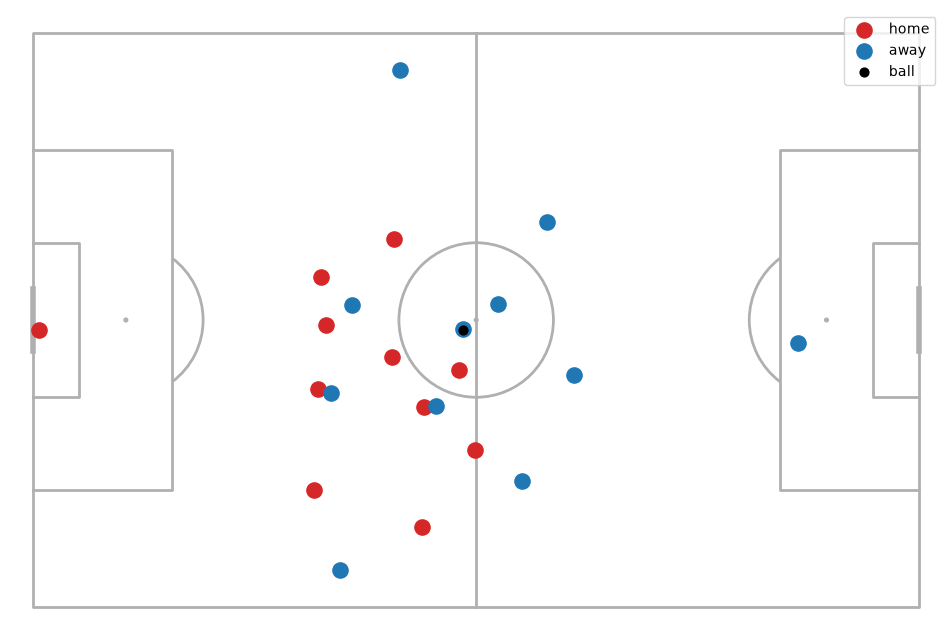

In [3]:
import matplotlib.pyplot as plt
from mplsoccer import Pitch

row = df.iloc[100]

pitch = Pitch(pitch_type="metricasports", pitch_length=105, pitch_width=68)
fig, ax = pitch.draw(figsize=(10, 6.5))

for team, color in [("home", "tab:red"), ("away", "tab:blue")]:
    xs = [row[c] for c in df.columns if c.startswith(team) and c.endswith("_x")]
    ys = [row[c] for c in df.columns if c.startswith(team) and c.endswith("_y")]
    pitch.scatter(xs, ys, ax=ax, color=color, s=120, label=team)

pitch.scatter(row["ball_x"], row["ball_y"], ax=ax, color="black", s=40, label="ball")
ax.legend()
plt.show()